# Validation of surface variables against surface gridded observations

In [1]:
import numpy as np
import regionmask
import xarray as xr
import xesmf
from glob import glob
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

/home/Raphael.Dussin/.conda/envs/rtofs_analysis/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Grids and remapping functions

In [2]:
def create_regular_grid(hres=1, Rearth=6378e3, c_cont=True):
    """Create a regular 2D latitude-longitude grid with a land/sea mask and cell area.
    Parameters
    ----------
    hres : float, optional
        Horizontal resolution of the grid in degrees. Default is 1.
    Rearth : float, optional
        Radius of the Earth in meters. Default is 6378e3.
    c_cont : bool, optional
        If True, returns the dataset variables as C-contiguous numpy arrays.
        This is useful for compatibility with xESMF's internal Fortran ordering.
        Default is True.
    Returns
    -------
    xarray.Dataset
        A dataset containing the grid variables:
        - 'lon', 'lat': 2D arrays of cell centers (degrees).
        - 'lon_b', 'lat_b': 2D arrays of cell boundaries (degrees).
        - 'area': 2D array of cell area in square meters.
        - 'mask': 2D land/sea mask.
    """
    ds = xesmf.util.grid_2d(0, 360, hres, -90, 90, hres)
    # compute cell area
    rfac = 2 * np.pi * Rearth / 360
    dx = rfac * hres * np.cos(2 * np.pi * ds["lat"] / 360)
    dy = rfac * hres
    ds["area"] = xr.DataArray(data=dx * dy, dims=("y", "x"))
    ds["mask"] = (
        regionmask.defined_regions.natural_earth_v5_0_0.land_110.mask(
            ds["lon"], ds["lat"]
        ).fillna(1.0)
    )

    if c_cont:
        out = xr.Dataset()
        # Force C-contiguous order so xESMF's internal transpose makes it F-contiguous
        out["lon"] = (ds["lon"].dims, np.ascontiguousarray(ds["lon"].values))
        out["lat"] = (ds["lat"].dims, np.ascontiguousarray(ds["lat"].values))
        out["lon_b"] = (ds["lon_b"].dims, np.ascontiguousarray(ds["lon_b"].values))
        out["lat_b"] = (ds["lat_b"].dims, np.ascontiguousarray(ds["lat_b"].values))
        out["area"] = (ds["area"].dims, np.ascontiguousarray(ds["area"].values))
        out["mask"] = (ds["mask"].dims, np.ascontiguousarray(ds["mask"].values))
        return out

    return ds

In [3]:
def create_grid_RTOFS(ostatic_path, c_cont=True):
    """ get coords from ocean static"""
    import xarray as xr
    import numpy as np

    ostatic = xr.open_dataset(ostatic_path)
    ds = xr.Dataset()

    ds["lon"] = xr.DataArray(data=ostatic["geolon"].values, dims=("y", "x"), attrs={"units": "degrees_east"})
    ds["lat"] = xr.DataArray(data=ostatic["geolon"].values, dims=("y", "x"), attrs={"units": "degrees_north"})

    ds["lon_b"] = xr.DataArray(data=ostatic["geolon_c"].values, dims=("y_b", "x_b"))
    ds["lat_b"] = xr.DataArray(data=ostatic["geolat_c"].values,dims=("y_b", "x_b"))
    ds["mask"] = xr.DataArray(data=ostatic["wet"].fillna(0.).values, dims=("y", "x"))

    if c_cont:
        out = xr.Dataset()
        # Force C-contiguous order so xESMF's internal transpose makes it F-contiguous
        out["lon"] = (ds["lon"].dims, np.ascontiguousarray(ds["lon"].values))
        out["lat"] = (ds["lat"].dims, np.ascontiguousarray(ds["lat"].values))
        out["lon_b"] = (ds["lon_b"].dims, np.ascontiguousarray(ds["lon_b"].values))
        out["lat_b"] = (ds["lat_b"].dims, np.ascontiguousarray(ds["lat_b"].values))
        out["mask"] = (ds["mask"].dims, np.ascontiguousarray(ds["mask"].values))
        return out
    return ds

In [4]:
# 1x1 degree grid
grid_1x1deg = create_regular_grid()

In [5]:
# RTOFS free
zstar_dir = "/scratch4/NCEPDEV/marine/Raphael.Dussin/freeruns_mom6sis2_GLBb008/GLBb008_mom6sis2_ERA5_zstar"
static_RTOFS = f"{zstar_dir}/20200101.ocean_static.nc"
grid_RTOFS = create_grid_RTOFS(static_RTOFS)

## create or load regridding

In [ ]:
%%time

import os

if not os.path.exists("../esmf_wgts/esmf_wgts_RTOFS_1x1.nc"):
    regrid_RTOFS = xesmf.Regridder(grid_RTOFS, grid_1x1deg, method="conservative_normed", periodic=True)
    regrid_RTOFS.to_netcdf("../esmf_wgts/esmf_wgts_RTOFS_1x1.nc")
else:
    regrid_RTOFS = xesmf.Regridder(grid_RTOFS, grid_1x1deg, method="conservative_normed", periodic=True, weights="../esmf_wgts/esmf_wgts_RTOFS_1x1.nc")

## 2. Read data

### 2.2 RTOFS free runs

In [ ]:
zstar_dir = "/scratch4/NCEPDEV/marine/Raphael.Dussin/freeruns_mom6sis2_GLBb008/GLBb008_mom6sis2_ERA5_zstar"
hycom1_dir = "/scratch4/NCEPDEV/marine/Raphael.Dussin/freeruns_mom6sis2_GLBb008/GLBb008_mom6sis2_ERA5_hycom1"

In [ ]:
zstar_monthly = xr.open_mfdataset(f"{zstar_dir}/*ocean_month.nc")
hycom1_monthly = xr.open_mfdataset(f"{hycom1_dir}/*ocean_month.nc")

## 3. Remap all to 1x1deg

In [ ]:
%%capture

sst_zstar = regrid_RTOFS(zstar_monthly["tos"])
sss_zstar = regrid_RTOFS(zstar_monthly["sos"])
ssh_zstar = regrid_RTOFS(zstar_monthly["zos"])

sst_hycom1 = regrid_RTOFS(hycom1_monthly["tos"])
sss_hycom1 = regrid_RTOFS(hycom1_monthly["sos"])
ssh_hycom1 = regrid_RTOFS(hycom1_monthly["zos"])

In [ ]:
%%capture
sst_zstar.load()
sss_zstar.load()
ssh_zstar.load()

sst_hycom1.load()
sss_hycom1.load()
ssh_hycom1.load()

In [ ]:
sst_zstar.to_dataset(name="sst").to_netcdf("../analysis_output/sst_GLBb008_ERA5_zstar_1m_1x1deg_2020-2025.nc")
sss_zstar.to_dataset(name="sss").to_netcdf("../analysis_output/sss_GLBb008_ERA5_zstar_1m_1x1deg_2020-2025.nc")
ssh_zstar.to_dataset(name="ssh").to_netcdf("../analysis_output/ssh_GLBb008_ERA5_zstar_1m_1x1deg_2020-2025.nc")

sst_hycom1.to_dataset(name="sst").to_netcdf("../analysis_output/sst_GLBb008_ERA5_hycom1_1m_1x1deg_2020-2025.nc")
sss_hycom1.to_dataset(name="sss").to_netcdf("../analysis_output/sss_GLBb008_ERA5_hycom1_1m_1x1deg_2020-2025.nc")
ssh_hycom1.to_dataset(name="ssh").to_netcdf("../analysis_output/ssh_GLBb008_ERA5_hycom1_1m_1x1deg_2020-2025.nc")

## Reload data

In [6]:
# reload
sst_zstar = xr.open_dataset("../analysis_output/sst_GLBb008_ERA5_zstar_1m_1x1deg_2020-2025.nc")["sst"]
sss_zstar = xr.open_dataset("../analysis_output/sss_GLBb008_ERA5_zstar_1m_1x1deg_2020-2025.nc")["sss"]
ssh_zstar = xr.open_dataset("../analysis_output/ssh_GLBb008_ERA5_zstar_1m_1x1deg_2020-2025.nc")["ssh"]

sst_hycom1 = xr.open_dataset("../analysis_output/sst_GLBb008_ERA5_hycom1_1m_1x1deg_2020-2025.nc")["sst"]
sss_hycom1 = xr.open_dataset("../analysis_output/sss_GLBb008_ERA5_hycom1_1m_1x1deg_2020-2025.nc")["sss"]
ssh_hycom1 = xr.open_dataset("../analysis_output/ssh_GLBb008_ERA5_hycom1_1m_1x1deg_2020-2025.nc")["ssh"]

## 4. Analysis

In [7]:
def plot_map(da, grid, vmin=None, vmax=None, cmap="RdBu_r", title="title"):
    """ make my nice map """

    da["lon"] = grid_1x1deg["lon"]
    da["lat"] = grid_1x1deg["lat"]
    f = plt.figure(figsize=[8,4])
    ax = plt.axes(projection=ccrs.Robinson(central_longitude=200))
    da.plot(ax=ax, x="lon", y="lat", 
            vmin=vmin, vmax=vmax,
            cmap=cmap,
            transform=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, color="grey")
    ax.coastlines()
    plt.title(title)
    return None

### 4.1 Average differences 2020-2025

#### 4.1.1 SST

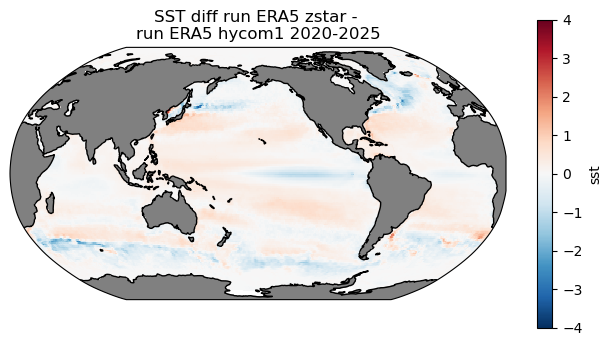

In [8]:
plot_map(sst_zstar.mean(dim="time") - sst_hycom1.mean(dim="time"), grid_1x1deg,
         vmin=-4, vmax=4, cmap="RdBu_r", title="SST diff run ERA5 zstar - \nrun ERA5 hycom1 2020-2025")

#### 4.1.2 SSS

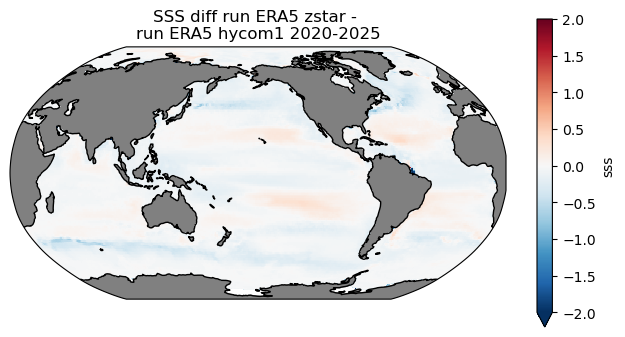

In [9]:
plot_map(sss_zstar.mean(dim="time") - sss_hycom1.mean(dim="time"), grid_1x1deg,
         vmin=-2, vmax=2, cmap="RdBu_r", title="SSS diff run ERA5 zstar - \nrun ERA5 hycom1 2020-2025")

#### 4.1.3 SSH

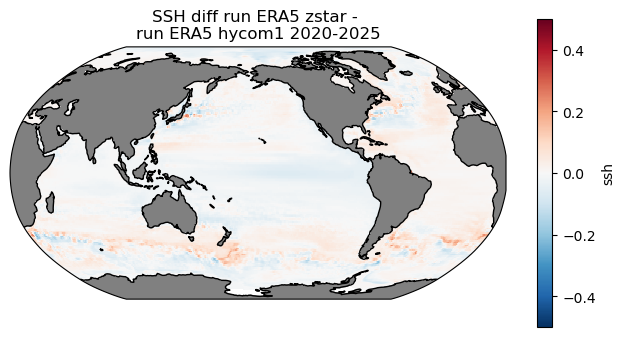

In [10]:
plot_map(ssh_zstar.mean(dim="time") - ssh_hycom1.mean(dim="time"), grid_1x1deg,
         vmin=-0.5, vmax=0.5, cmap="RdBu_r", title="SSH diff run ERA5 zstar - \nrun ERA5 hycom1 2020-2025")

### 4.2 Difference with observations

#### 4.2.1 SST

In [11]:
ostia = xr.open_dataset("/scratch3/NCEPDEV/marine/Raphael.Dussin/rtofs-tools/compare_obs/sst_ostia_1m_2020-2025.nc")

In [12]:
sst_ostia = ostia["analysed_sst"]
sst_ostia["time"] = sst_zstar["time"]

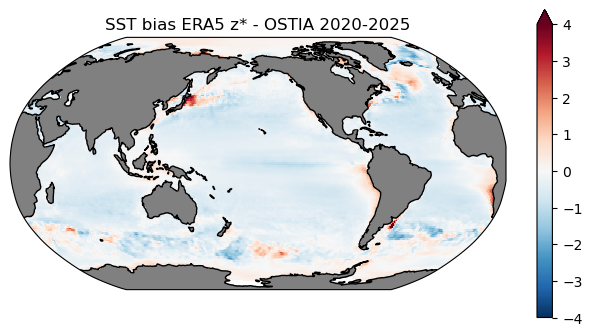

In [13]:
plot_map(sst_zstar.mean(dim="time") - sst_ostia.mean(dim="time") + 273.15, grid_1x1deg,
         vmin=-4, vmax=4, cmap="RdBu_r", title="SST bias ERA5 z* - OSTIA 2020-2025")

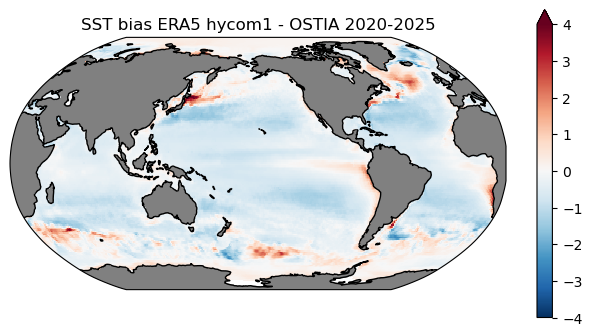

In [14]:
plot_map(sst_hycom1.mean(dim="time") - sst_ostia.mean(dim="time") + 273.15, grid_1x1deg,
         vmin=-4, vmax=4, cmap="RdBu_r", title="SST bias ERA5 hycom1 - OSTIA 2020-2025")

#### 4.2.2 SSS

In [15]:
cmems_sss = xr.open_dataset("/scratch3/NCEPDEV/marine/Raphael.Dussin/rtofs-tools/compare_obs/sss_cmems_1m_2020-2025.nc")

In [16]:
sos_cmems = cmems_sss["sos"]
sos_cmems["time"] = sss_zstar["time"]

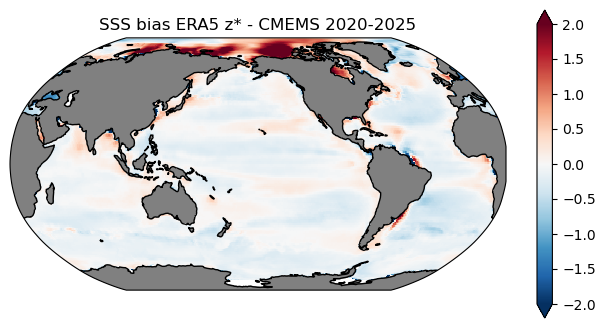

In [17]:
plot_map(sss_zstar.mean(dim="time") - sos_cmems.mean(dim="time"), grid_1x1deg,
         vmin=-2, vmax=2, cmap="RdBu_r", title="SSS bias ERA5 z* - CMEMS 2020-2025")

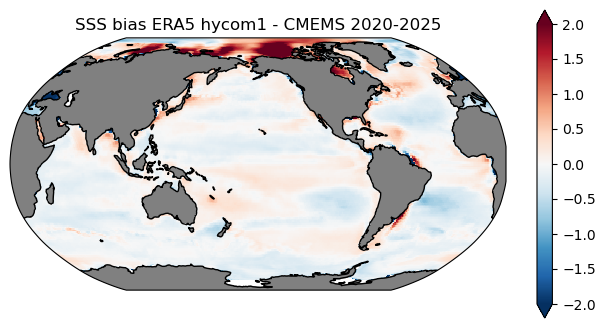

In [18]:
plot_map(sss_hycom1.sel(time=slice("2020-01", "2021-12")).mean(dim="time") - sos_cmems.mean(dim="time"), grid_1x1deg,
         vmin=-2, vmax=2, cmap="RdBu_r", title="SSS bias ERA5 hycom1 - CMEMS 2020-2025")

#### 4.2.2 SSH

In [19]:
cmems_ssh = xr.open_dataset("/scratch3/NCEPDEV/marine/Raphael.Dussin/rtofs-tools/compare_obs/ssh_cmems_1m_2020-2025.nc")

In [20]:
ssh_cmems = cmems_ssh["adt"]
ssh_cmems["time"] = ssh_zstar["time"]

In [21]:
def remove_glo_mean(ssh, grid_1x1deg):
    sshglo = ssh.weighted(grid_1x1deg["area"]*grid_1x1deg["mask"]).mean(dim=("x", "y"))
    return ssh - sshglo

In [22]:
ssh_cmems = remove_glo_mean(ssh_cmems, grid_1x1deg)
ssh_zstar = remove_glo_mean(ssh_zstar, grid_1x1deg)
ssh_hycom1 = remove_glo_mean(ssh_hycom1, grid_1x1deg)

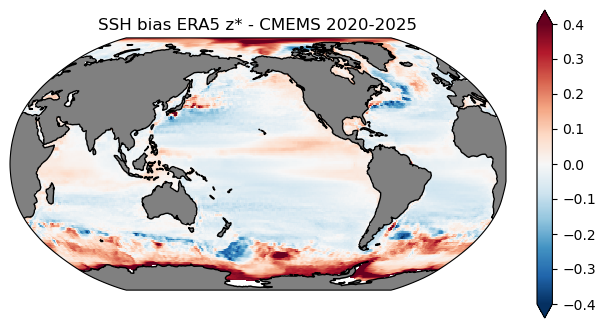

In [23]:
plot_map(ssh_zstar.mean(dim="time") - ssh_cmems.mean(dim="time"), grid_1x1deg,
         vmin=-0.4, vmax=0.4, cmap="RdBu_r", title="SSH bias ERA5 z* - CMEMS 2020-2025")

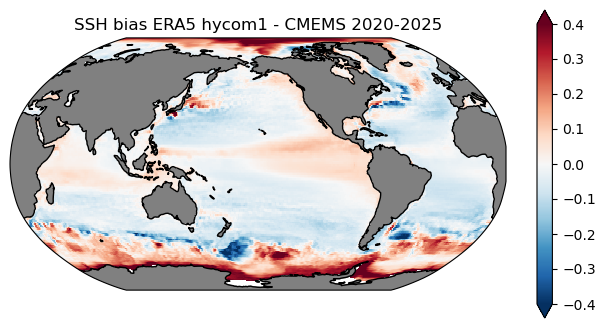

In [24]:
plot_map(ssh_hycom1.mean(dim="time") - ssh_cmems.mean(dim="time"), grid_1x1deg,
         vmin=-0.4, vmax=0.4, cmap="RdBu_r", title="SSH bias ERA5 hycom1 - CMEMS 2020-2025")

## RMSE for SST, SSS, SSH

In [25]:
from xhistogram.xarray import histogram

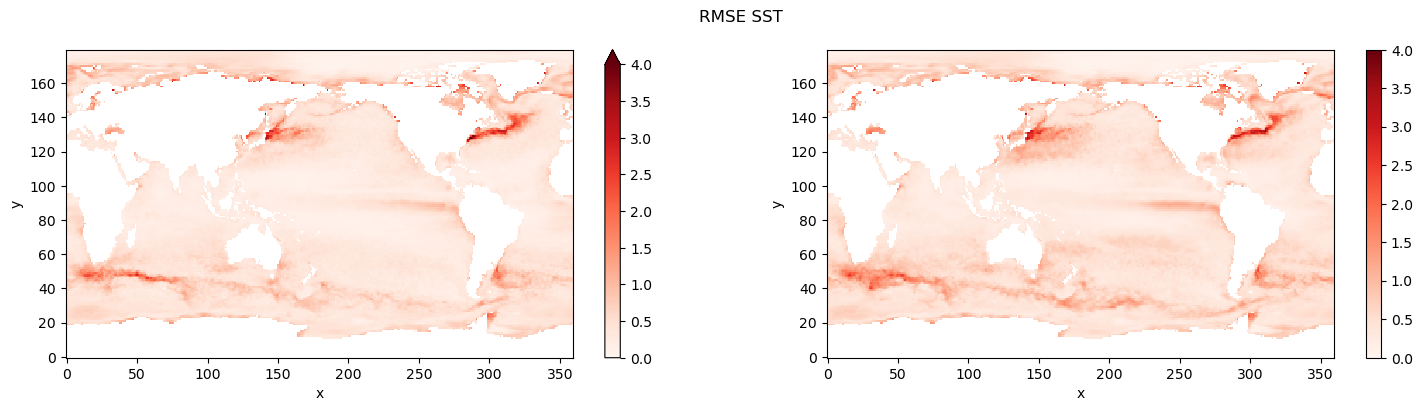

In [30]:
f , axs = plt.subplots(ncols=2, figsize=[18,4])
(sst_zstar - sst_ostia + 273.15).std(dim="time").plot(ax=axs[0], vmin=0, vmax=4, cmap="Reds")
(sst_hycom1 - sst_ostia + 273.15).std(dim="time").plot(ax=axs[1], vmin=0, vmax=4, cmap="Reds")
f.suptitle("RMSE SST")
plt.show()

In [27]:
sst_bins = np.linspace(0,4,25)
da_zstar = (sst_zstar - sst_ostia + 273.15).std(dim="time") ; da_zstar.name = "sst bias"
da_hycom1 = (sst_hycom1 - sst_ostia + 273.15).std(dim="time") ; da_hycom1.name = "sst bias"
weights = 100*(grid_1x1deg["mask"]) / grid_1x1deg["mask"].sum()
weights = grid_1x1deg["mask"]

hist_sst_zstar = histogram(da_zstar, bins=sst_bins, weights=weights)
hist_sst_hycom1 = histogram(da_hycom1, bins=sst_bins, weights=weights)

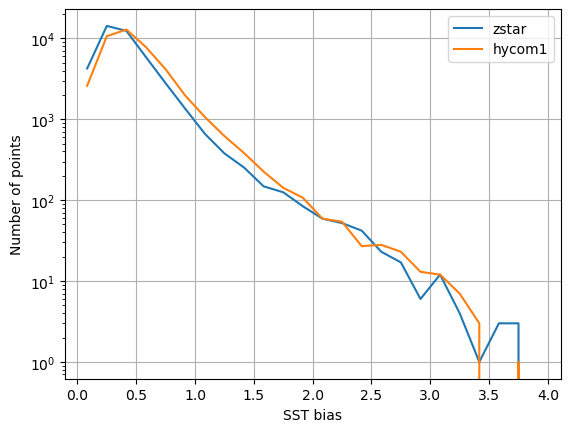

In [32]:
ax = plt.axes()
hist_sst_zstar.plot(ax=ax, yscale="log", label="zstar")
hist_sst_hycom1.plot(ax=ax, yscale="log", label="hycom1")
ax.legend()
ax.set_ylabel("Number of points")
ax.set_xlabel("SST bias")
ax.grid()

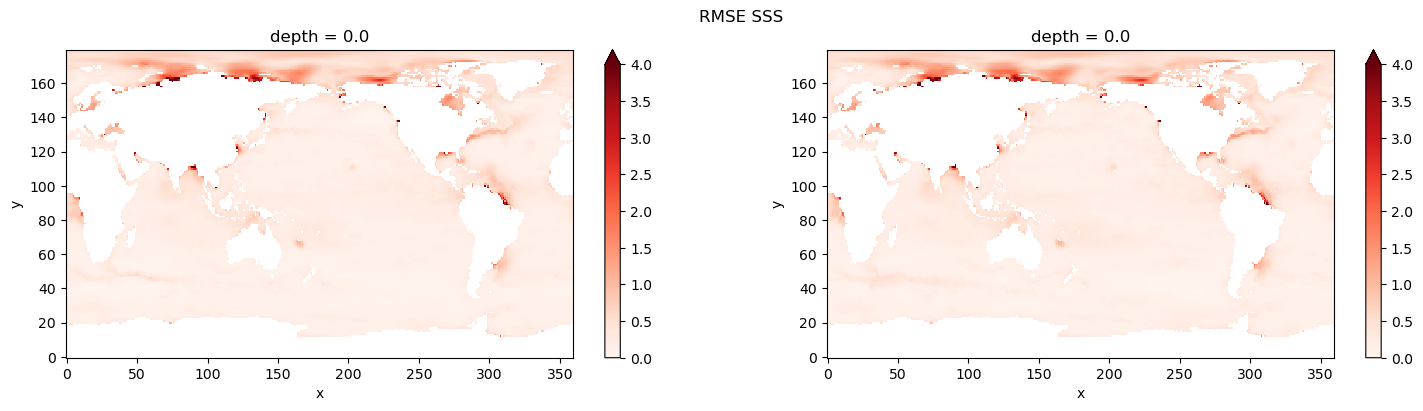

In [33]:
f , axs = plt.subplots(ncols=2, figsize=[18,4])
(sss_zstar - sos_cmems).std(dim="time").plot(ax=axs[0], vmin=0, vmax=4, cmap="Reds")
(sss_hycom1 - sos_cmems).std(dim="time").plot(ax=axs[1], vmin=0, vmax=4, cmap="Reds")
f.suptitle("RMSE SSS")
plt.show()

In [34]:
sss_bins = np.linspace(0,7,21)
da_zstar = (sss_zstar - sos_cmems).std(dim="time") ; da_zstar.name = "sss bias"
da_hycom1 = (sss_hycom1 - sos_cmems).std(dim="time") ; da_hycom1.name = "sss bias"
weights = (grid_1x1deg["mask"]) #/ grid_1x1deg["mask"].sum()

hist_sss_zstar = histogram(da_zstar, bins=sss_bins, weights=weights)
hist_sss_hycom1 = histogram(da_hycom1, bins=sss_bins, weights=weights)

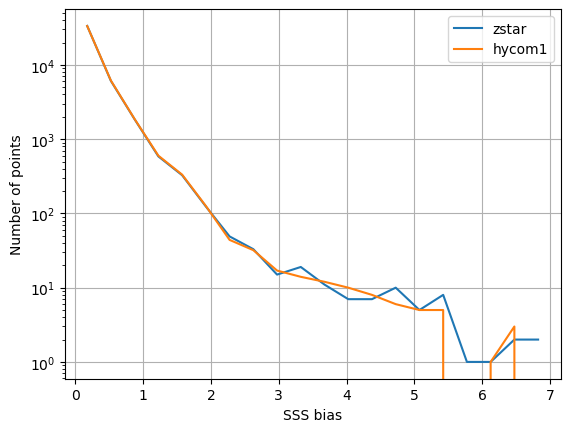

In [35]:
ax = plt.axes()
hist_sss_zstar.plot(ax=ax, yscale="log", label="zstar")
hist_sss_hycom1.plot(ax=ax, yscale="log", label="hycom1")
ax.legend()
ax.set_ylabel("Number of points")
ax.set_xlabel("SSS bias")
ax.grid()

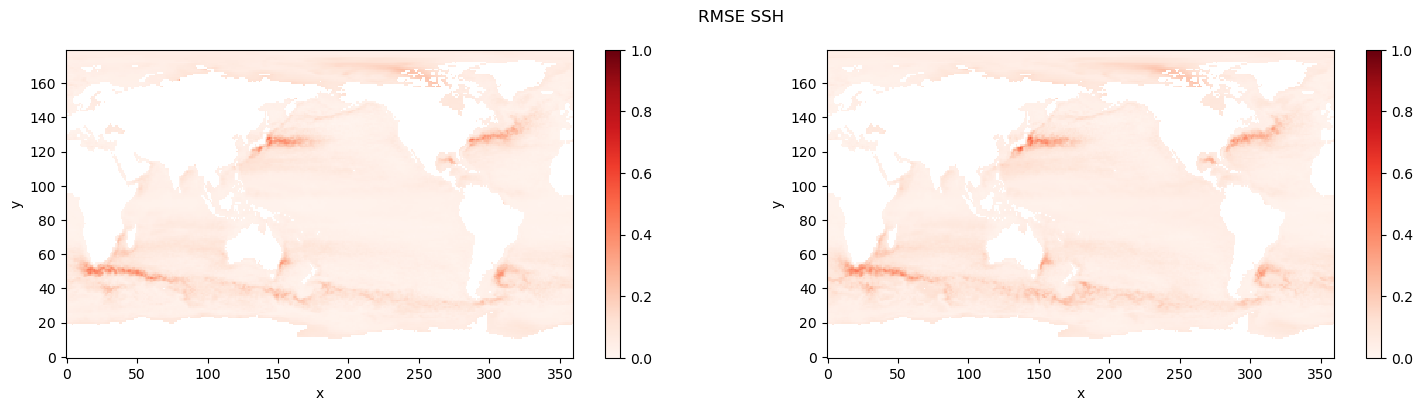

In [36]:
f , axs = plt.subplots(ncols=2, figsize=[18,4])
(ssh_zstar - ssh_cmems).std(dim="time").plot(ax=axs[0], vmin=0, vmax=1, cmap="Reds")
(ssh_hycom1 - ssh_cmems).std(dim="time").plot(ax=axs[1], vmin=0, vmax=1, cmap="Reds")
f.suptitle("RMSE SSH")
plt.show()

In [37]:
ssh_bins = np.linspace(0,0.6,11)
da_zstar = (ssh_zstar - ssh_cmems).std(dim="time") ; da_zstar.name = "ssh bias"
da_hycom1 = (ssh_hycom1 - ssh_cmems).std(dim="time") ; da_hycom1.name = "ssh bias"
weights = 100*(grid_1x1deg["mask"]) / grid_1x1deg["mask"].sum()
weights = grid_1x1deg["mask"]

hist_ssh_zstar = histogram(da_zstar, bins=ssh_bins, weights=weights)
hist_ssh_hycom1 = histogram(da_hycom1, bins=ssh_bins, weights=weights)

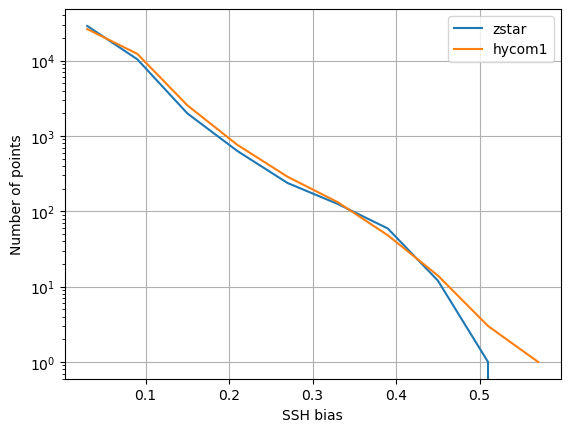

In [38]:
ax = plt.axes()
hist_ssh_zstar.plot(ax=ax, yscale="log", label="zstar")
hist_ssh_hycom1.plot(ax=ax, yscale="log", label="hycom1")
ax.legend()
ax.set_ylabel("Number of points")
ax.set_xlabel("SSH bias")
ax.grid()